# Bakery Lab: your first sales forecast

We are building a small learning prototype for a possible bakery food-waste product. Our first question is whether we can forecast a store's sales one week ahead.

By the end, you will have loaded real data, checked its limitations, plotted sales patterns, and compared a simple forecast with a machine-learning model.

**Before you start:** install the packages in `requirements.txt` using the instructions in `README.md`. Open this notebook with the project's Python environment and run cells from top to bottom. The bundled data works offline.

**Read every chart as scaled sales, not item counts.** Negative values are valid because the source data was transformed. This notebook does not calculate kilograms of waste, money saved, or how many pastries to bake.

## 1. Find the project and import the tools

Python packages are collections of reusable tools. Here we use pandas for tables, NumPy for numbers, and Matplotlib for charts. The project module `analysis.py` contains the shared forecasting code so the notebook and dashboard use the same experiment.

In [1]:
from pathlib import Path
import sys

# Find analysis.py whether Jupyter starts in this folder or the workspace.
working_folder = Path.cwd().resolve()
candidates = [working_folder, working_folder / "outputs" / "bakery-prototype"]
candidates.extend(working_folder.parents)
PROJECT = next((folder for folder in candidates if (folder / "analysis.py").is_file()), None)
if PROJECT is None:
    raise FileNotFoundError("Open this notebook from the bakery-prototype folder.")

if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from analysis import load_data, evaluate_store

plt.rcParams.update({
    "figure.figsize": (12, 4.5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.15,
    "font.size": 11,
})
print("Project:", PROJECT.name)
print("Python:", sys.version.split()[0])

Project: bakery-prototype
Python: 3.12.14


`PROJECT` is a folder path. Adding it to `sys.path` lets Python import our own module. The plotting settings only change how the charts look; they do not change the data.

## 2. Load and inspect the real data

The source is [Green AI Hub Mittelstand's Reduce Foodwaste Dataset](https://github.com/Green-AI-Hub-Mittelstand/Reduce-Foodwaste-Dataset). We use its bundled training file, pinned to commit `3bde2d0f9b256ffc800932ac8574a695909f59a5`. It contains 5,142 observations across nine stores, from August 2021 through November 2023.

The original notice and description are preserved in `data/LICENSE` and `data/README.md`. Source details are in `data/source.json`.

In [2]:
data = load_data(PROJECT / "data" / "train.csv")

print(f"Rows: {len(data):,}")
print(f"Stores: {data['store'].nunique()}")
print(f"Dates: {data['date'].min():%Y-%m-%d} to {data['date'].max():%Y-%m-%d}")
display(data.head())
display(data.dtypes.rename("data type").to_frame())

Rows: 5,142
Stores: 9
Dates: 2021-08-02 to 2023-11-30


,date,store,is_state_holiday,is_school_holiday,is_special_day,temperature_max,temperature_min,temperature_mean,sunshine_sum,precipitation_sum,sales,unsold,ordered
0,2023-03-02,store_0,normal_day,normal_day,normal_day,2.8,-0.1,1.809091,0,0.0,-1.204614,-0.078293,-1.049955
1,2023-03-03,store_0,normal_day,normal_day,normal_day,5.8,2.4,4.800000,1,0.0,-1.043714,-0.027102,-0.870327
2,2023-03-04,store_0,normal_day,normal_day,normal_day,6.6,2.6,4.654545,18,0.0,-0.733573,0.740761,-0.336233
3,2023-03-05,store_0,normal_day,normal_day,normal_day,5.0,0.2,2.845455,92,2.3,-1.216273,2.165574,-0.432035
4,2023-03-06,store_0,normal_day,school_holiday,normal_day,4.6,2.0,3.309091,205,0.0,-1.442466,1.013779,-0.987684


,data type
date,datetime64[us]
store,str
is_state_holiday,str
is_school_holiday,str
is_special_day,str
temperature_max,float64
temperature_min,float64
temperature_mean,float64
sunshine_sum,int64
precipitation_sum,float64


A pandas `DataFrame` is a table. Each row here describes one store on one date. `head()` displays the first five rows. The date column is parsed as dates so we can sort and compare it correctly.

A row is not an individual transaction or an individual pastry.

In [3]:
coverage = data.groupby("store").agg(
    recorded_days=("date", "size"),
    first_day=("date", "min"),
    last_day=("date", "max"),
    sales_available=("sales", "count"),
    unsold_available=("unsold", "count"),
    ordered_available=("ordered", "count"),
)
coverage["unsold_coverage_pct"] = (
    100 * coverage["unsold_available"] / coverage["recorded_days"]
).round(1)
display(coverage)

missing_pct = (
    data[["sales", "unsold", "ordered"]]
    .isna().mean().mul(100).round(1).rename("missing %")
)
display(missing_pct.to_frame())

,recorded_days,first_day,last_day,sales_available,unsold_available,ordered_available,unsold_coverage_pct
store,,,,,,,
store_0,273,2023-03-02,2023-11-30,273,269,269,98.5
store_1,847,2021-08-02,2023-11-30,847,467,467,55.1
store_2,61,2023-10-01,2023-11-30,61,55,55,90.2
store_3,242,2023-04-02,2023-11-30,242,225,225,93.0
store_4,847,2021-08-02,2023-11-30,847,491,491,58.0
store_5,847,2021-08-02,2023-11-30,847,473,473,55.8
store_6,331,2022-12-24,2023-11-30,331,320,320,96.7
store_7,847,2021-08-02,2023-11-30,847,477,477,56.3
store_8,847,2021-08-02,2023-11-30,847,449,449,53.0


,missing %
sales,0.0
unsold,37.3
ordered,37.3


Missing information is different from zero. An empty `unsold` cell does not mean nothing was left over. The coverage percentage tells us how often a value was recorded; it is **not a waste percentage**.

The `sales`, `unsold`, and `ordered` values are transformed. We must preserve negative values and must not divide these columns to estimate physical waste rates. Unsold items might also be donated or used later rather than discarded.

## 3. Explore one store

We will start with `store_1`, which has a long history. You can later change `STORE_ID` and rerun the following cells. A shorter history may be insufficient for the forecast experiment.

In [4]:
STORE_ID = "store_1"

store_data = data.loc[data["store"].eq(STORE_ID)].sort_values("date").copy()
if store_data.empty:
    raise ValueError(f"No data found for {STORE_ID}")

# Use a real calendar. Missing dates stay missing rather than becoming zero.
calendar = pd.date_range(store_data["date"].min(), store_data["date"].max(), freq="D")
sales = store_data.set_index("date")["sales"].reindex(calendar)
sales.index.name = "date"

print(f"{STORE_ID}: {len(store_data):,} recorded days")
print(f"Missing calendar days: {sales.isna().sum()}")
display(store_data.tail())

store_1: 847 recorded days
Missing calendar days: 4


,date,store,is_state_holiday,is_school_holiday,is_special_day,temperature_max,temperature_min,temperature_mean,sunshine_sum,precipitation_sum,sales,unsold,ordered
1115,2023-11-26,store_1,normal_day,normal_day,normal_day,1.1,-1.5,0.172727,124,0.0,0.388063,NaN,NaN
1116,2023-11-27,store_1,normal_day,normal_day,normal_day,2.0,-0.2,0.890909,0,0.5,-1.353854,NaN,NaN
1117,2023-11-28,store_1,normal_day,normal_day,normal_day,-1.0,-4.1,-2.181818,141,0.0,-1.358518,NaN,NaN
1118,2023-11-29,store_1,normal_day,normal_day,normal_day,0.9,-0.6,0.145455,0,1.9,-0.789538,-0.010039,-0.604478
1119,2023-11-30,store_1,normal_day,normal_day,normal_day,0.5,-6.2,-2.827273,108,0.0,-0.861827,-0.103889,-0.705069


`loc` selects rows that match a condition. `sort_values` puts them in date order. Reindexing against a daily calendar preserves gaps, which matters because "seven days ago" should mean seven calendar days, not seven rows ago.

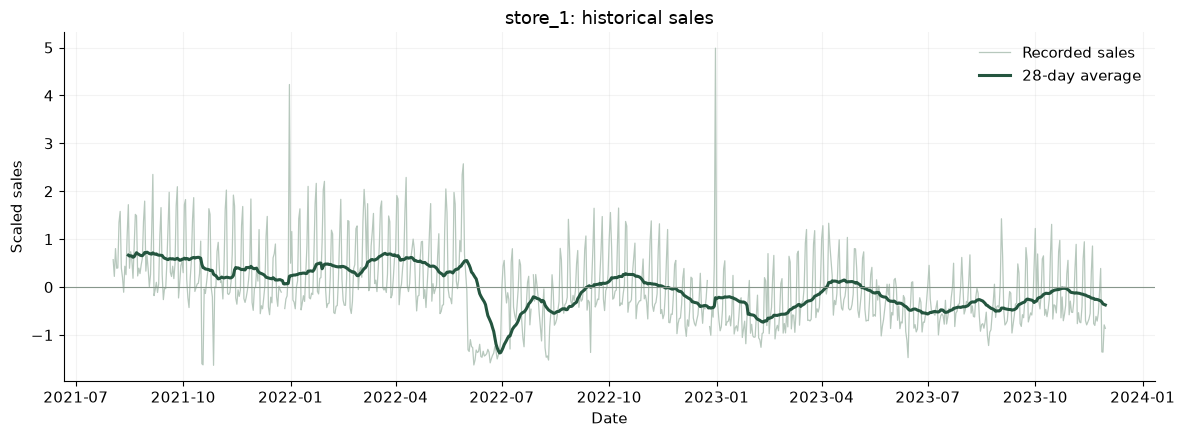

In [5]:
fig, ax = plt.subplots()
ax.plot(sales.index, sales, color="#b7c8bd", linewidth=0.9, label="Recorded sales")
ax.plot(
    sales.index,
    sales.rolling(28, min_periods=14).mean(),
    color="#24553f", linewidth=2.2, label="28-day average",
)
ax.axhline(0, color="#87978c", linewidth=0.8)
ax.set(title=f"{STORE_ID}: historical sales", xlabel="Date", ylabel="Scaled sales")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

The pale line shows the daily records. The darker line smooths them over the preceding 28 calendar days. It is a descriptive chart, not a forecast. Its units cannot be converted into pastry counts from the available information.

,mean scaled sales,recorded days
Mon,-0.441457,122
Tue,-0.435646,122
Wed,-0.441895,121
Thu,-0.363243,122
Fri,-0.024931,121
Sat,0.673350,120
Sun,0.832768,119


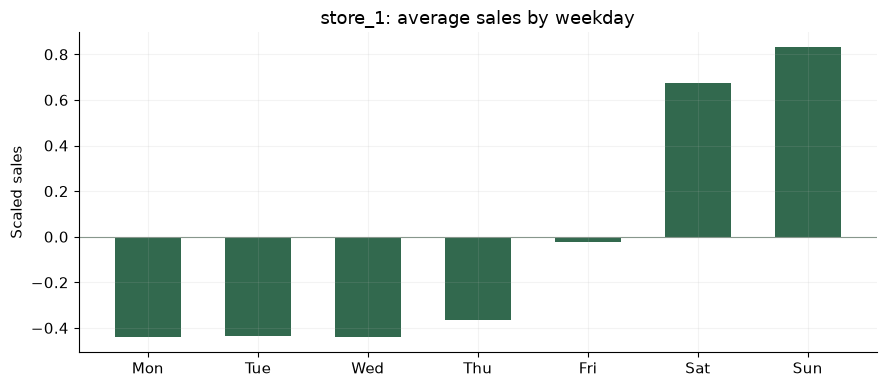

In [6]:
weekday_summary = (
    pd.DataFrame({"weekday": sales.index.dayofweek, "sales": sales.to_numpy()})
    .groupby("weekday")["sales"]
    .agg(["mean", "count"])
    .reindex(range(7))
)
weekday_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
weekday_summary.index = weekday_names
display(weekday_summary.rename(columns={"mean": "mean scaled sales", "count": "recorded days"}))

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(np.arange(7), weekday_summary["mean"], color="#32694e", width=0.6)
ax.set_xticks(np.arange(7), weekday_names)
ax.axhline(0, color="#87978c", linewidth=0.8)
ax.set(title=f"{STORE_ID}: average sales by weekday", ylabel="Scaled sales")
fig.tight_layout()
plt.show()

A weekly pattern gives us a simple starting point for forecasting. These averages describe all observed history; we do not feed these full-history averages into the model. The forecasting code below constructs features using only information available before each forecast is issued.

## 4. Compare two honest week-ahead forecasts

The **baseline** repeats sales from the same weekday in the previous week. This is a useful reference: a more complicated model should earn its place.

The **ML model** is a Random Forest with fixed settings. It uses earlier sales and calendar information:
- Sales from 7, 14, 21, and 28 calendar days before the target date.
- Rolling sales features shifted back seven days.
- Calendar features and holiday flags that are available in advance.

The model does not use the target week's actual weather, unsold quantities, or ordered quantities.

We reserve the store's final **56 calendar days** for evaluation. Forecasts are issued in seven-day blocks. The model can learn from completed weeks before predicting the next one, but it cannot see observations from the week it is predicting. Both methods are evaluated on the same dates. This matches a repeated weekly forecasting exercise rather than a random train/test split.

In [7]:
result = evaluate_store(data, STORE_ID, holdout_days=56)
evaluation = result["evaluation"]
predictions = pd.DataFrame(result["predictions"]).copy()

if not evaluation.get("eligible", False):
    raise ValueError(evaluation.get("reason", "This store has too little training history."))

predictions["date"] = pd.to_datetime(predictions["date"])
predictions = predictions.sort_values("date").reset_index(drop=True)

metrics = pd.DataFrame([
    {
        "method": "Repeat last week",
        "MAE: scaled points": evaluation.get("baseline_mae"),
        "RMSE: scaled points": evaluation.get("baseline_rmse"),
    },
    {
        "method": "Random Forest",
        "MAE: scaled points": evaluation.get("ml_mae"),
        "RMSE: scaled points": evaluation.get("ml_rmse"),
    },
]).set_index("method")
display(metrics.round(4))
print(f"Compared dates: {len(predictions)}")
print("ML error reduction (%):", evaluation.get("improvement_pct"))
display(predictions.head(7))

,MAE: scaled points,RMSE: scaled points
method,,
Repeat last week,0.2122,0.2963
Random Forest,0.1614,0.2243


Compared dates: 56
ML error reduction (%): 23.93150217717683


,date,origin,horizon,actual,baseline,ml
0,2023-10-06,2023-10-05,1,-0.159929,-0.318498,-0.366912
1,2023-10-07,2023-10-05,2,0.586274,0.448692,0.367756
2,2023-10-08,2023-10-05,3,0.651566,1.222878,0.714341
3,2023-10-09,2023-10-05,4,-0.588996,-0.260200,-0.487168
4,2023-10-10,2023-10-05,5,-0.465406,0.691208,-0.227397
5,2023-10-11,2023-10-05,6,-0.619311,-0.295179,-0.399853
6,2023-10-12,2023-10-05,7,-0.470070,-0.456079,-0.435665


**MAE** means mean absolute error: calculate the distance between each prediction and the observed value, then average those distances. Lower is better. **RMSE** gives extra weight to large errors.

The reported error reduction compares ML MAE with baseline MAE. A positive percentage means the model has lower error; a negative percentage means it has higher error. It is not an accuracy score or a percentage of food saved.

The `origin` column records when that week's forecasts were issued. `horizon` records how far ahead a target day is. The Random Forest settings are fixed before this comparison; we are not searching these final dates for the best settings.

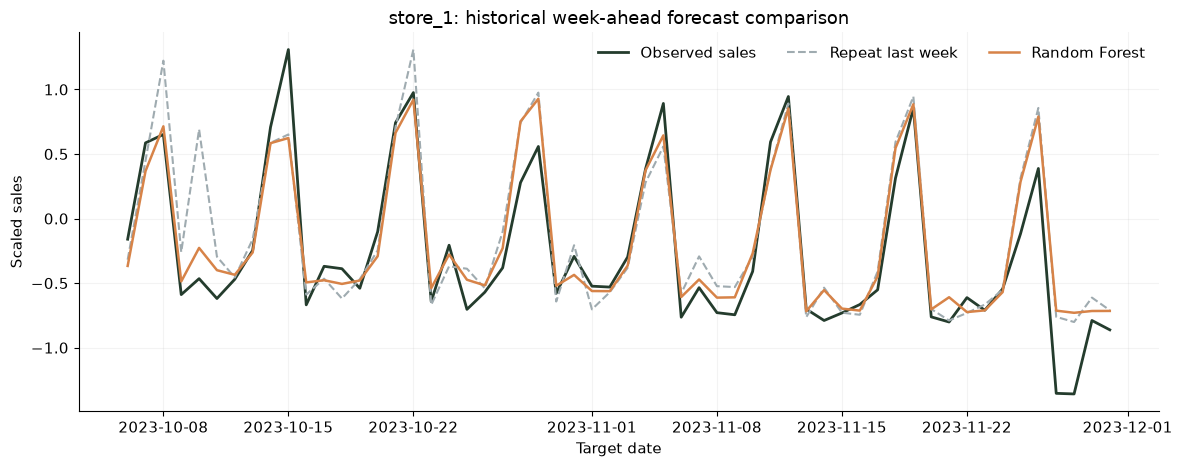

In [8]:
fig, ax = plt.subplots(figsize=(12, 4.8))
ax.plot(
    predictions["date"], predictions["actual"],
    color="#243c2d", linewidth=2, label="Observed sales",
)
ax.plot(
    predictions["date"], predictions["baseline"],
    color="#9fabb0", linewidth=1.5, linestyle="--", label="Repeat last week",
)
ax.plot(
    predictions["date"], predictions["ml"],
    color="#d78348", linewidth=1.8, label="Random Forest",
)
ax.set(
    title=f"{STORE_ID}: historical week-ahead forecast comparison",
    xlabel="Target date", ylabel="Scaled sales",
)
ax.legend(frameon=False, ncol=3)
fig.tight_layout()
plt.show()

These are predictions for dates in the historical evaluation period, with observed sales shown for comparison. They are not live forecasts for your local bakery.

Avoid judging a model only by how smooth its line looks. The errors on the same unseen dates are the meaningful comparison.

In [9]:
error_check = predictions.copy()
error_check["baseline_absolute_error"] = (
    error_check["actual"] - error_check["baseline"]
).abs()
error_check["ml_absolute_error"] = (
    error_check["actual"] - error_check["ml"]
).abs()

print("Dates with the largest ML errors:")
largest_errors = error_check.sort_values("ml_absolute_error", ascending=False).head(10).copy()
numeric_columns = largest_errors.select_dtypes(include="number").columns
largest_errors[numeric_columns] = largest_errors[numeric_columns].round(4)
display(largest_errors)


Dates with the largest ML errors:


,date,origin,horizon,actual,baseline,ml,baseline_absolute_error,ml_absolute_error
9,2023-10-15,2023-10-12,3,1.3092,0.6516,0.6238,0.6576,0.6854
52,2023-11-27,2023-11-23,4,-1.3539,-0.7616,-0.7133,0.5923,0.6405
53,2023-11-28,2023-11-23,5,-1.3585,-0.8012,-0.7299,0.5573,0.6286
22,2023-10-28,2023-10-26,2,0.2785,0.7425,0.7527,0.4640,0.4742
50,2023-11-25,2023-11-23,2,-0.1180,0.3134,0.2846,0.4314,0.4026
51,2023-11-26,2023-11-23,3,0.3881,0.8568,0.7898,0.4687,0.4018
23,2023-10-29,2023-10-26,3,0.5583,0.9757,0.9280,0.4174,0.3697
30,2023-11-05,2023-11-02,3,0.8918,0.5583,0.6444,0.3335,0.2473
4,2023-10-10,2023-10-05,5,-0.4654,0.6912,-0.2274,1.1566,0.2380
39,2023-11-14,2023-11-09,5,-0.7895,-0.5354,-0.5540,0.2542,0.2356


Investigate mistakes before adding complexity. Do the difficult dates cluster around holidays? Did the pattern change? Is data missing? These are hypotheses to check, not explanations established by the chart.

Observed sales can be lower than demand if products sell out. We do not have reliable sellout records, so our target is **recorded sales**, not true customer demand.

## 5. Your next exercises

1. Change `STORE_ID` to another store with enough history and run the notebook again. Describe one difference in its weekly pattern.
2. Pick one of the largest errors and examine the surrounding dates and calendar flags.
3. Read `evaluate_store` in `analysis.py`. Find where it chooses its training cutoff and where it makes the baseline prediction.
4. Write a short explanation of what would make a useful dashboard for a bakery owner.

For a later modelling experiment, use an earlier validation period to choose features or settings, then keep a later period untouched for a final check. Repeatedly choosing models from the same test results makes those results less trustworthy.

### What this first prototype does not establish

The source scaling procedure is not described well enough to reconstruct raw item counts or audit when its transformation parameters were fitted. This exercise therefore evaluates the supplied scaled series. It does not establish operational forecast accuracy on raw sales, reduced discards, saved money, or customer willingness to pay.

A future bakery pilot would need records of production, sales, sellouts, leftover handling, and actual discards. Public data lets us learn and build now; feedback and real records will guide the business later.